# Expected R&D spend benchmark

**ML Zoomcamp 2026 midterm project**

**Goal:** predict the R&D spend we'd expect for a company, given its size, sector, profitability and location.
The prediction acts as a benchmark: is a company's reported R&D typical, unusually high or unusually low for its profile?

**Data:** EU Industrial R&D Investment Scoreboard panel (2003–2024), trimmed to the columns below.

| Column | Meaning |
|---|---|
| `company`, `company_name` | Short and long company name |
| `year` | Financial year |
| `new_country`, `region_12_new` | Country and world region of headquarters |
| `icb3_short`, `icb3_name` | Sector: 11 broad groups and 39 detailed sectors |
| `rnd_24` | **Target:** R&D investment, € million (2024 euros) |
| `netsales_24`, `capex_24`, `profit_24`, `mcap_24` | Net sales, capital expenditure, operating profit, market cap (€m, 2024 euros) |
| `emp` | Number of employees |
| `year_inc_new` | Year of incorporation (useful for company age) |

## 1. Setup and load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/scoreboard_panel.csv')
df.head()

,company,company_name,year,new_country,region_12_new,icb3_short,icb3_name,rnd_24,netsales_24,emp,capex_24,profit_24,mcap_24,year_inc_new
0,AMAZON,"AMAZON.COM, INC.",2024,US,US,ICT software,Software & Computer Services,65318.281985,614071.614207,1556000.0,79891.231110,66024.641448,2.220511e+06,1994.0
1,ALPHABET,ALPHABET INC.,2024,US,US,ICT software,Software & Computer Services,46131.485225,336912.118587,183323.0,50567.908365,108181.730677,1.064665e+06,1998.0
2,META,"META PLATFORMS, INC.",2024,US,US,ICT software,Software & Computer Services,41985.754163,158341.515064,74067.0,35861.006834,66407.738955,1.228620e+06,2004.0
3,MICROSOFT,MICROSOFT CORPORATION,2024,US,US,ICT software,Software & Computer Services,31271.537203,271175.281548,228000.0,62133.987872,123715.468284,2.834358e+06,1981.0
4,APPLE,APPLE INC.,2024,US,US,ICT hardware,Technology Hardware & Equipment,30195.398980,376393.300606,164000.0,9093.271730,118602.367889,3.164133e+06,1977.0


## 2. Data cleaning

Checks for missing values, impossible values and outliers, followed by a cleaning step that applies the decisions.

In [2]:
# How big is the data, and how much is missing?
print(df.shape)
df.isnull().mean().round(3)

(96836, 14)


company          0.000
company_name     0.000
year             0.000
new_country      0.000
region_12_new    0.000
icb3_short       0.001
icb3_name        0.001
rnd_24           0.186
netsales_24      0.153
emp              0.217
capex_24         0.233
profit_24        0.139
mcap_24          0.372
year_inc_new     0.000
dtype: float64

**Size and missing values**

The dataset has 96,836 rows (one per company per year) and 14 columns.

- **Target (`rnd_24`):** 18.6% of rows have no R&D figure. These rows can't be used to train the model, so they will be dropped.
- **Financial features:** missing values range from 14% (`profit_24`) to 23% (`capex_24`). Market capitalisation (`mcap_24`) is missing in 37% of rows, probably because not all companies are listed on a stock exchange.
- **Categorical features:** company, year, country, region and sector are almost complete (sector is missing in 0.1% of rows).

Many of the rows missing the target may also be missing other figures, so I'll check the missing values again after dropping them.

In [3]:
# How many rows can’t be used because the target is missing or not positive?
print('Missing R&D:', df['rnd_24'].isnull().sum())
print('Zero or negative R&D:', (df['rnd_24'] <= 0).sum())

Missing R&D: 18039
Zero or negative R&D: 228


**Unusable target values**

- 18,039 rows have no R&D figure.
- 228 rows have zero or negative R&D. Negative R&D isn't possible, and companies with zero R&D shouldn't appear in a scoreboard of top R&D investors, so these are most likely reporting errors. They would also break the log transform used for the target later.

Both groups will be dropped, leaving 78,569 rows.

In [4]:
# Are there odd values in the numbers?
pd.set_option('display.float_format', '{:,.1f}'.format)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,"96,836.0","2,013.4",5.7,"2,003.0","2,009.0","2,013.0","2,018.0","2,024.0"
rnd_24,"78,797.0",210.2,"1,019.6",0.0,12.7,36.9,104.8,"65,318.3"
netsales_24,"82,033.0","5,927.0","176,126.3",-9.0,159.2,766.6,"3,077.7","50,140,463.0"
emp,"75,861.0","16,981.3","46,059.9",0.0,757.0,"3,705.0","12,834.0","1,608,000.0"
capex_24,"74,245.0",374.4,"1,773.3",-716.1,5.9,33.8,153.7,"79,891.2"
profit_24,"83,386.0",565.9,"5,764.9","-35,339.6",0.2,45.2,248.0,"1,314,803.2"
mcap_24,"60,795.0","9,129.6","51,808.0",0.0,367.0,"1,327.6","4,797.1","3,164,133.0"
year_inc_new,"96,826.0","1,979.4",38.5,"1,654.0","1,968.0","1,995.0","2,003.0","2,023.0"


**Value ranges and outliers**

All money columns are in € millions, converted by the Scoreboard from each company's reporting currency (36 currencies) at the end-2024 exchange rate.

- The typical (median) company spends €37m a year on R&D on sales of about €770m. The averages are much higher (€210m R&D) because a few very large companies pull them up. R&D, sales, employees and capex are all heavily right-skewed, so they will be log-transformed.
- **Data error:** the largest net sales figure (€50 trillion, Ecopetrol, 2015) is impossible. In the original file, Ecopetrol's 2015 figures are in Colombian pesos but labelled as US dollars, so they were converted at the wrong exchange rate. This row has zero R&D, so it is removed with the other zero-R&D rows.
- **Negative values:** 14 rows have negative net sales and 27 have negative capex, which isn't possible. These will be treated as missing values. Negative operating profit is genuine (loss-making companies) and is kept.
- **Zero sales:** 1,280 rows have zero net sales. These are likely early-stage companies (e.g. biotech) investing in R&D before generating revenue, so they are kept.
- **Year of incorporation** ranges from 1654 to 2023. The earliest (Orkla, Norway) is genuine.

In [5]:
# Keep only rows with a positive R&D figure (this also drops missing values)
df_clean = df[df['rnd_24'] > 0].copy()

# Negative sales and capex, and zero employees, aren't possible: treat them as missing
for col in ['netsales_24', 'capex_24']:
    df_clean.loc[df_clean[col] < 0, col] = np.nan
df_clean.loc[df_clean['emp'] == 0, 'emp'] = np.nan

# Drop rows where R&D per employee is implausible (over €5m per head):
# either the R&D figure or the employee count is wrong
rnd_per_emp = df_clean['rnd_24'] / df_clean['emp']
df_clean = df_clean[~(rnd_per_emp > 5)]

print(df_clean.shape)
(df_clean.isnull().mean() * 100).round(1)

(78501, 14)


company          0.0
company_name     0.0
year             0.0
new_country      0.0
region_12_new    0.0
icb3_short       0.0
icb3_name        0.0
rnd_24           0.0
netsales_24      3.0
emp              9.8
capex_24        10.6
profit_24        1.6
mcap_24         25.3
year_inc_new     0.0
dtype: float64

**Cleaning**

- Dropped the rows with missing, zero or negative R&D.
- Replaced negative net sales and capex values, and zero employee counts (9 rows), with missing values.
- Dropped 68 rows (from 41 companies) where R&D spend per employee was over €5m. The typical company spends about €11,000 per employee, so these figures are implausible: either the R&D figure or the employee count is wrong. Examples: Marine Current Turbines (UK, 2012) reports €3.3bn of R&D with 33 employees, against €10m the following year (most likely a units error); Huawei (2008) lists 19 employees.

This leaves 78,501 rows. Most of the missing feature values were in the rows without an R&D figure. After cleaning, net sales and profit are almost complete (3% and 2% missing), employees and capex are about 10% missing, and market capitalisation is still 25% missing. The remaining gaps will be filled before training. Tree-based models such as XGBoost can also handle missing values directly.

## 3. Exploratory data analysis

### 3.1 The target

The distribution of R&D spend, on a normal and a log scale.

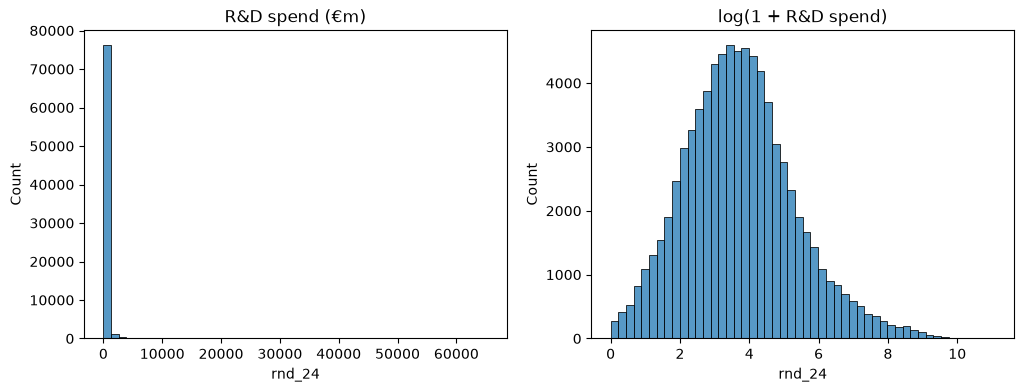

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean['rnd_24'], bins=50, ax=axes[0])
axes[0].set_title('R&D spend (€m)')

sns.histplot(np.log1p(df_clean['rnd_24']), bins=50, ax=axes[1])
axes[1].set_title('log(1 + R&D spend)')

plt.show()

**Target distribution**

R&D spend is extremely right-skewed: most companies spend tens of millions of euros a year, but a few spend tens of billions (the maximum is Amazon, €65bn in 2024). On a normal scale almost all rows fall into a single bar.

After a log transform (`np.log1p`), the distribution is close to bell-shaped, centred around 3.6 (about €37m). The model will therefore predict log R&D spend, and predictions will be converted back to euros with `np.expm1`.

### 3.2 Features: distributions, sectors and regions

The distributions of the numerical features, how the data is spread across sectors and regions, and how many years each company appears in.

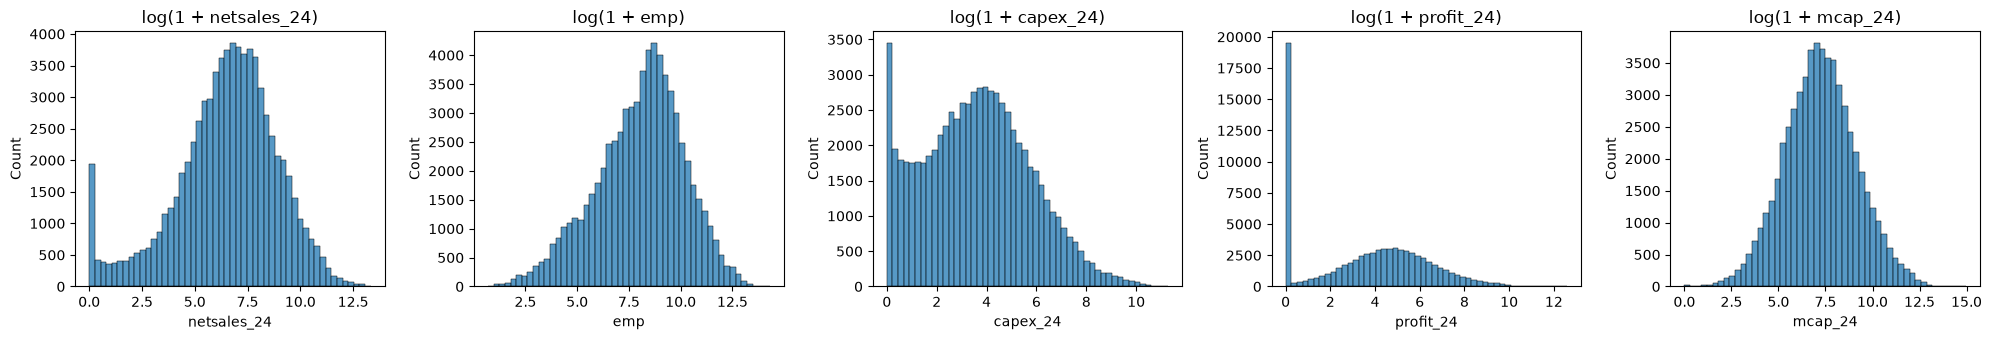

icb3_short
Health                      15507
ICT hardware                14910
Others                      10912
Industrials                  9877
ICT software                 9826
Automotive                   4843
Chemicals                    3895
Energy                       2563
Construction & Materials     2398
Financial                    2387
Aerospace & Defence          1344
Name: count, dtype: int64 

region_12_new
US       21537
EU       21243
ROW      15170
China    11939
Japan     8612
Name: count, dtype: int64 

count   6,295.0
mean       12.5
std         6.0
min         1.0
25%         8.0
50%        12.0
75%        18.0
max        22.0
Name: year, dtype: float64


In [7]:
num_cols = ['netsales_24', 'emp', 'capex_24', 'profit_24', 'mcap_24']

# Distributions of the numeric features on a log scale
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, num_cols):
    sns.histplot(np.log1p(df_clean[col].clip(lower=0)), bins=50, ax=ax)
    ax.set_title(f'log(1 + {col})')
plt.tight_layout()
plt.show()

# How the rows split by sector and region
print(df_clean['icb3_short'].value_counts(), '\n')
print(df_clean['region_12_new'].value_counts(), '\n')

# How many years each company appears in
years_per_company = df_clean.groupby('company')['year'].nunique()
print(years_per_company.describe())

**Feature distributions**

- **Net sales, employees and market capitalisation** are right-skewed like the target and look bell-shaped after a log transform, so they will be log-transformed.
- **Net sales** has a small spike at zero (about 2,600 rows with sales under €1m): early-stage companies investing in R&D before earning revenue.
- **Capex** also has many very small values (about 7,300 rows under €1m), typical of software and biotech companies that invest in people rather than physical assets.
- **Operating profit** can't be log-transformed directly because 24.5% of rows are loss-making. It will be used as a **profit margin** (profit ÷ sales) instead. Losses are most common in Health (55% of rows) and ICT software (31%), sectors where companies often invest heavily in R&D before generating profits.

**Sectors and regions**

All 11 sectors are well represented (from 1,344 rows for Aerospace & Defence to 15,507 for Health). The five regions are the US, EU, China, Japan and "rest of world" (ROW), which includes the UK.

**Years per company**

The 6,295 companies appear in 12 years on average (up to 22). Because each company appears many times, the train/test split must keep each company's rows together, otherwise the model would be tested on companies it has already seen.

### 3.3 R&D intensity by sector

R&D spend as a percentage of net sales, compared across sectors, and the companies that spend more on R&D than their total sales.

icb3_short
Energy                      0.7
Construction & Materials    1.4
Industrials                 2.4
Others                      2.5
Chemicals                   2.7
Financial                   2.7
Automotive                  3.4
Aerospace & Defence         4.4
ICT hardware                7.5
ICT software               15.2
Health                     19.9
Name: rnd_intensity, dtype: float64


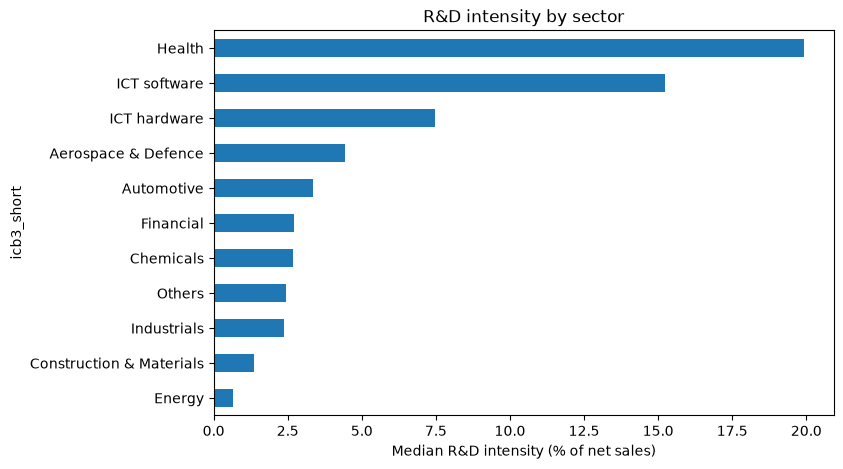


Rows where R&D is more than sales: 4952 (6.6%)
icb3_short
Health          4183
ICT hardware     205
Others           168
ICT software     135
Industrials       66
Name: count, dtype: int64


In [8]:
# R&D intensity = R&D as a % of net sales (for analysis only, never a model feature)
eda = df_clean[df_clean['netsales_24'] > 0].copy()
eda['rnd_intensity'] = eda['rnd_24'] / eda['netsales_24'] * 100

# Median intensity per sector, as a table and a bar chart
by_sector = eda.groupby('icb3_short')['rnd_intensity'].median().sort_values()
print(by_sector)

by_sector.plot(kind='barh', figsize=(8, 5))
plt.xlabel('Median R&D intensity (% of net sales)')
plt.title('R&D intensity by sector')
plt.show()

# Companies spending more on R&D than their total sales
high = eda[eda['rnd_intensity'] > 100]
print('\nRows where R&D is more than sales:', len(high), f'({len(high) / len(eda):.1%})')
print(high['icb3_short'].value_counts().head(5))

**R&D intensity by sector**

R&D intensity is R&D spend as a percentage of net sales. It is used here only to understand the data: because it is calculated from the target, it is never used as a model feature (that would leak the answer into the model).

- Median intensity varies about 30-fold between sectors: from 0.7% in Energy and 1.4% in Construction & Materials, to 15.2% in ICT software and 19.9% in Health. Sector is therefore likely to be one of the most important features.
- 4,952 rows (6.6%) have R&D spend greater than total net sales. Most of these (4,183) are in Health: mainly biotech companies investing heavily in R&D before they have products on the market. This matches the high share of loss-making Health companies seen in the feature analysis.

### 3.4 Feature importance

Correlation with log R&D for the numerical features, and mutual information for the categorical features.

log_mcap_24       0.7
log_capex_24      0.6
log_netsales_24   0.6
log_emp           0.6
year              0.2
age               0.2
profit_margin     0.1
dtype: float64 



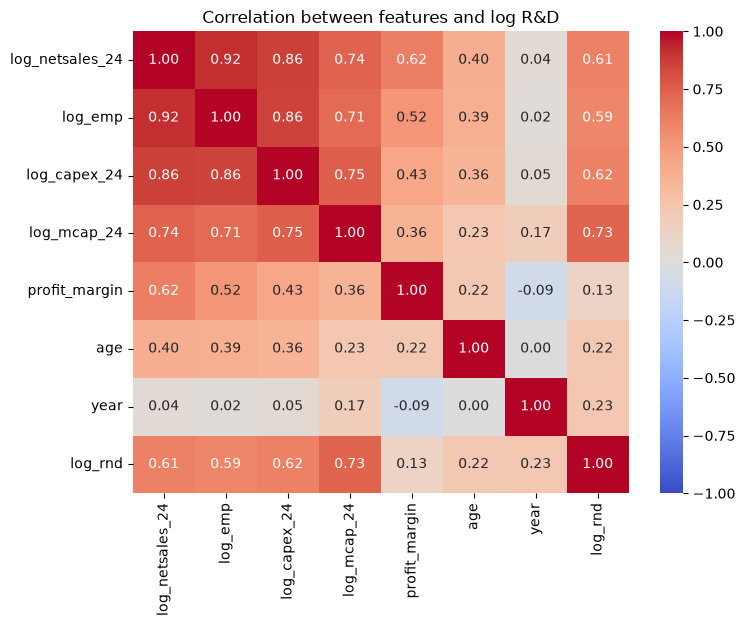

new_country     0.2
region_12_new   0.1
icb3_name       0.1
icb3_short      0.1
dtype: float64 

icb3_name       0.4
icb3_short      0.3
new_country     0.1
region_12_new   0.1
dtype: float64


In [9]:
from sklearn.feature_selection import mutual_info_regression

# Build the features as the model will see them
fi = df_clean.copy()
fi['log_rnd'] = np.log1p(fi['rnd_24'])
for col in ['netsales_24', 'emp', 'capex_24', 'mcap_24']:
    fi['log_' + col] = np.log1p(fi[col])
fi['profit_margin'] = (fi['profit_24'] / fi['netsales_24']).clip(-1, 1)
fi['age'] = fi['year'] - fi['year_inc_new']

# 1. Correlation of each number feature with log R&D
num_features = ['log_netsales_24', 'log_emp', 'log_capex_24', 'log_mcap_24',
                'profit_margin', 'age', 'year']
print(fi[num_features].corrwith(fi['log_rnd']).sort_values(ascending=False), '\n')

# Correlation heatmap: how the features relate to R&D and to each other
plt.figure(figsize=(8, 6))
sns.heatmap(fi[num_features + ['log_rnd']].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between features and log R&D')
plt.show()

# 2. Mutual information of each category feature with log R&D
cat_features = ['icb3_short', 'icb3_name', 'region_12_new', 'new_country']
X_cat = fi[cat_features].apply(lambda s: s.astype('category').cat.codes)
mi = mutual_info_regression(X_cat, fi['log_rnd'], discrete_features=True, random_state=1)
print(pd.Series(mi, index=cat_features).sort_values(ascending=False), '\n')

# 3. The same, but with R&D intensity (R&D relative to sales) as the target
has_sales = fi['netsales_24'] > 0
log_intensity = np.log1p(fi.loc[has_sales, 'rnd_24'] / fi.loc[has_sales, 'netsales_24'])
mi2 = mutual_info_regression(X_cat[has_sales], log_intensity, discrete_features=True, random_state=1)
print(pd.Series(mi2, index=cat_features).sort_values(ascending=False))

**Feature importance**

*Numerical features* (correlation with log R&D):
- Company size is the strongest predictor: market capitalisation (0.73), capex (0.62), net sales (0.61) and employees (0.59), all on a log scale.
- The size features are strongly correlated with each other (e.g. net sales and employees: 0.92), so they carry overlapping information. Regularisation will help the linear model handle this.
- Profit margin (0.13), company age (0.22) and year (0.23) are weak on their own but may help in combination with other features.

*Categorical features* (mutual information with log R&D):
- On its own, sector says little about the *amount* of R&D (0.05 for the 11 broad sectors), because company size dominates.
- But sector is the strongest categorical predictor of R&D *intensity* (R&D relative to sales): 0.33 for the broad sectors and 0.43 for the 39 detailed sectors. Sector tells you how much a company spends on R&D *for its size*, so the model needs size and sector together. Tree-based models should capture this interaction better than a linear model.
- Country (0.17) scores higher than region (0.14), partly because mutual information tends to favour features with many categories (55 countries against 5 regions).

## 4. Feature engineering and validation split

The features are built from the EDA findings, and the data is split by company to avoid the same company appearing in both training and test data.

In [10]:
from sklearn.model_selection import train_test_split

# --- 1. Feature engineering ---
def prepare_features(df):
    X = pd.DataFrame(index=df.index)
    for col in ['netsales_24', 'emp', 'capex_24']:
        X['log_' + col] = np.log1p(df[col])
    X['profit_margin'] = (df['profit_24'] / df['netsales_24']).clip(-1, 1)
    X['age'] = (df['year'] - df['year_inc_new']).clip(lower=0)
    X['year'] = df['year']
    X['sector'] = df['icb3_name']
    X['country'] = df['new_country']
    return X

numerical = ['log_netsales_24', 'log_emp', 'log_capex_24', 'profit_margin', 'age', 'year']
categorical = ['sector', 'country']

# --- 2. Split by company: 60% train, 20% validation, 20% test ---
companies = df_clean['company'].unique()
companies_full_train, companies_test = train_test_split(companies, test_size=0.2, random_state=1)
companies_train, companies_val = train_test_split(companies_full_train, test_size=0.25, random_state=1)

df_train = df_clean[df_clean['company'].isin(companies_train)]
df_val = df_clean[df_clean['company'].isin(companies_val)]
df_test = df_clean[df_clean['company'].isin(companies_test)]
print('Companies:', len(companies_train), len(companies_val), len(companies_test))
print('Rows:     ', len(df_train), len(df_val), len(df_test))

# --- 3. Build features and fill gaps, using the training set's medians ---
X_train = prepare_features(df_train)
X_val = prepare_features(df_val)
X_test = prepare_features(df_test)

train_medians = X_train[numerical].median()
for X in [X_train, X_val, X_test]:
    X[numerical] = X[numerical].fillna(train_medians)
    X[categorical] = X[categorical].fillna('unknown')

# --- 4. Target: log R&D ---
y_train = np.log1p(df_train['rnd_24']).values
y_val = np.log1p(df_val['rnd_24']).values
y_test = np.log1p(df_test['rnd_24']).values

print('Missing values left:', X_train.isnull().sum().sum(), X_val.isnull().sum().sum(), X_test.isnull().sum().sum())
X_train.head()

Companies: 3777 1259 1259
Rows:      47238 15588 15675
Missing values left: 0 0 0


,log_netsales_24,log_emp,log_capex_24,profit_margin,age,year,sector,country
1,12.7,12.1,10.8,0.3,26.0,2024,Software & Computer Services,US
3,12.5,12.3,11.0,0.5,43.0,2024,Software & Computer Services,US
6,12.2,8.3,10.4,0.1,55.0,2024,Electronic & Electrical Equipment,South Korea
7,12.7,13.4,9.7,0.1,120.0,2024,Automobiles & Parts,Germany
9,10.8,11.6,10.0,-0.2,56.0,2024,Technology Hardware & Equipment,US


**Feature engineering**

Features used: log net sales, log employees, log capex, profit margin (profit ÷ sales, capped between −100% and +100%), company age (negative ages set to zero), year, detailed sector (39 categories) and country.

Left out deliberately:
- **Market capitalisation**: the strongest single predictor, but only listed companies have one. Most companies claiming R&D tax relief, especially SMEs, are private, so including it would make the model unusable for its intended purpose.
- **Company name**: the model would memorise individual companies rather than learn general patterns.
- **R&D intensity**: calculated from the target, so it would leak the answer.

Missing numerical values are filled with the training set's median, and missing categories with "unknown".

**Validation approach**

Each company appears in the data many times (12 years on average), so a random split would put different years of the same company in both the training and test sets, giving an over-optimistic score. Instead, the data is split **by company**: 60% of companies for training, 20% for validation and 20% for testing. The test score therefore measures how well the model predicts R&D for a company it has never seen, which matches the intended use (sense-checking a company that isn't in the training data).

## 5. Model training

Four models are trained on the training set and compared on the validation set. The metric is RMSE on log R&D; `np.exp(RMSE)` gives the typical factor by which predictions are off.

### 5.1 Linear model (Ridge regression)

In [11]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Ridge

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# Turn the feature tables into numbers (one-hot encoding for sector and country)
dv = DictVectorizer(sparse=False)
X_train_dv = dv.fit_transform(X_train.to_dict(orient='records'))
X_val_dv = dv.transform(X_val.to_dict(orient='records'))

# Dumb baseline: predict the training average for every company
baseline = rmse(y_val, np.full_like(y_val, y_train.mean()))
print(f'Baseline (always predict the average): RMSE={baseline:.3f}  (off by a factor of {np.exp(baseline):.2f})\n')

# Ridge regression with different regularisation strengths
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    model = Ridge(alpha=alpha)
    model.fit(X_train_dv, y_train)
    y_pred = model.predict(X_val_dv)
    score = rmse(y_val, y_pred)
    print(f'alpha={alpha:<6} RMSE={score:.3f}  (off by a factor of {np.exp(score):.2f})')

Baseline (always predict the average): RMSE=1.592  (off by a factor of 4.91)

alpha=0.01   RMSE=0.917  (off by a factor of 2.50)
alpha=0.1    RMSE=0.917  (off by a factor of 2.50)
alpha=1      RMSE=0.917  (off by a factor of 2.50)
alpha=10     RMSE=0.917  (off by a factor of 2.50)
alpha=100    RMSE=0.919  (off by a factor of 2.51)
alpha=1000   RMSE=0.946  (off by a factor of 2.57)


**5.1 Linear model (Ridge regression)**

Sector and country are one-hot encoded with `DictVectorizer` (95 features in total). Model quality is measured as RMSE on log R&D; `np.exp(RMSE)` gives the typical factor by which predictions are off.

| Model | Validation RMSE | Typical error |
|---|---|---|
| Baseline (always predict the average) | 1.592 | × 4.9 |
| Ridge (alpha = 0.01 to 10) | 0.917 | × 2.5 |
| Ridge (alpha = 1,000) | 0.946 | × 2.6 |

- The linear model roughly halves the typical error compared with the baseline.
- Results are almost identical for alpha between 0.01 and 10, so overfitting isn't a problem with this many rows. Without any regularisation (alpha = 0), the model becomes unstable because the one-hot encoded columns overlap, so a small amount of regularisation is needed. **alpha = 1** is used.
- A typical error of ×2.5 is a starting point. A linear model can't easily capture the interaction between sector and size found in the EDA, so tree-based models are expected to do better.

### 5.2 Decision tree

In [12]:
from sklearn.tree import DecisionTreeRegressor

# Step 1: tune the depth
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=1)
    dt.fit(X_train_dv, y_train)
    score = rmse(y_val, dt.predict(X_val_dv))
    print(f'max_depth={str(depth):<5} RMSE={score:.3f}  (off by a factor of {np.exp(score):.2f})')

# Step 2: for the best depths, tune the minimum leaf size
scores = []
for depth in [8, 10, 12, 15]:
    for leaf in [1, 5, 10, 20, 50, 100, 200]:
        dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        dt.fit(X_train_dv, y_train)
        scores.append((depth, leaf, rmse(y_val, dt.predict(X_val_dv))))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'rmse'])
df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='rmse').round(3)

max_depth=1     RMSE=1.312  (off by a factor of 3.71)
max_depth=2     RMSE=1.210  (off by a factor of 3.35)
max_depth=3     RMSE=1.153  (off by a factor of 3.17)
max_depth=4     RMSE=1.089  (off by a factor of 2.97)
max_depth=5     RMSE=1.057  (off by a factor of 2.88)
max_depth=6     RMSE=1.029  (off by a factor of 2.80)
max_depth=8     RMSE=0.992  (off by a factor of 2.70)
max_depth=10    RMSE=0.964  (off by a factor of 2.62)
max_depth=15    RMSE=1.040  (off by a factor of 2.83)
max_depth=20    RMSE=1.083  (off by a factor of 2.95)
max_depth=None  RMSE=1.145  (off by a factor of 3.14)


max_depth,8,10,12,15
min_samples_leaf,,,,
1,1.0,1.0,1.0,1.0
5,1.0,1.0,1.0,1.0
10,1.0,1.0,1.0,1.0
20,1.0,1.0,1.0,1.0
50,1.0,0.9,0.9,0.9
100,1.0,1.0,1.0,1.0
200,1.0,1.0,1.0,1.0


**5.2 Decision tree**

Tuned `max_depth` first, then `min_samples_leaf` for the best depths.

- Validation RMSE improves with depth up to `max_depth=10` (0.964), then gets worse (1.145 with no depth limit): deeper trees start memorising the training companies (overfitting).
- Requiring at least 50 companies per leaf reduces overfitting. Best combination: **`max_depth=12`, `min_samples_leaf=50`: RMSE 0.939** (typical error × 2.56).
- A single tree is slightly worse than Ridge (0.917), because it predicts a limited set of average values. Ensembles of many trees (random forest, XGBoost) are expected to do better.

### 5.3 Random forest

In [13]:
from sklearn.ensemble import RandomForestRegressor

# Step 1: how many trees?
for n in [10, 25, 50, 100, 200]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train_dv, y_train)
    score = rmse(y_val, rf.predict(X_val_dv))
    print(f'n_estimators={n:<4} RMSE={score:.3f}  (off by a factor of {np.exp(score):.2f})')

# Step 2: with 100 trees, tune depth and minimum leaf size
scores = []
for depth in [10, 15, 20, None]:
    for leaf in [1, 5, 20]:
        rf = RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                   random_state=1, n_jobs=-1)
        rf.fit(X_train_dv, y_train)
        scores.append((str(depth), leaf, rmse(y_val, rf.predict(X_val_dv))))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'rmse'])
df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='rmse').round(3)

n_estimators=10   RMSE=0.879  (off by a factor of 2.41)
n_estimators=25   RMSE=0.857  (off by a factor of 2.36)
n_estimators=50   RMSE=0.849  (off by a factor of 2.34)
n_estimators=100  RMSE=0.844  (off by a factor of 2.32)
n_estimators=200  RMSE=0.840  (off by a factor of 2.32)


max_depth,10,15,20,None
min_samples_leaf,,,,
1,0.9,0.9,0.8,0.8
5,0.9,0.9,0.8,0.8
20,0.9,0.9,0.9,0.9


**5.3 Random forest**

Tuned the number of trees first, then `max_depth` and `min_samples_leaf` with 100 trees.

- Validation RMSE improves from 0.879 (10 trees) to 0.844 (100 trees), with little further gain at 200 trees (0.840), so 100 trees are used.
- Best combination: **`max_depth=None`, `min_samples_leaf=5`: RMSE 0.843** (typical error × 2.32).
- Unlike the single decision tree, the forest works best without a depth limit: averaging many trees cancels out the overfitting of individual deep trees.
- The random forest clearly beats Ridge (0.917), confirming that tree-based models capture the combination of company size and sector better than a linear model.

### 5.4 XGBoost

Step 1: eta
eta=0.3   best RMSE=0.810 after 68 rounds
eta=0.1   best RMSE=0.795 after 243 rounds
eta=0.05  best RMSE=0.798 after 490 rounds


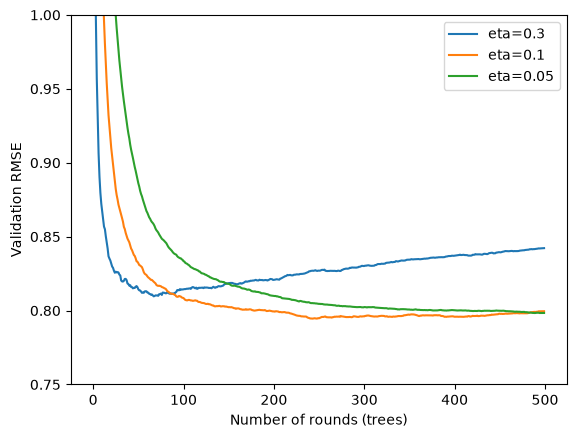

Step 2: max_depth (eta=0.1)
max_depth=3   best RMSE=0.816 after 475 rounds
max_depth=4   best RMSE=0.808 after 464 rounds
max_depth=6   best RMSE=0.795 after 243 rounds
max_depth=8   best RMSE=0.798 after 171 rounds
max_depth=10  best RMSE=0.809 after 154 rounds

Step 3: min_child_weight (eta=0.1, max_depth=6)
min_child_weight=1   best RMSE=0.795 after 243 rounds
min_child_weight=10  best RMSE=0.804 after 257 rounds
min_child_weight=30  best RMSE=0.805 after 229 rounds


In [14]:
import xgboost as xgb

features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train_dv, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val_dv, label=y_val, feature_names=features)

def train_xgb(eta=0.3, max_depth=6, min_child_weight=1, rounds=500):
    """Train XGBoost and return the best round, its validation RMSE and the full RMSE history."""
    params = {
        'eta': eta,
        'max_depth': max_depth,
        'min_child_weight': min_child_weight,
        'objective': 'reg:squarederror',
        'seed': 1,
        'verbosity': 1,
    }
    history = {}
    xgb.train(params, dtrain, num_boost_round=rounds,
              evals=[(dval, 'val')], evals_result=history, verbose_eval=False)
    val_rmse = history['val']['rmse']
    best_round = int(np.argmin(val_rmse)) + 1
    return best_round, min(val_rmse), val_rmse

# Step 1: learning rate
print('Step 1: eta')
curves = {}
for eta in [0.3, 0.1, 0.05]:
    best_round, best_rmse, curves[eta] = train_xgb(eta=eta)
    print(f'eta={eta:<5} best RMSE={best_rmse:.3f} after {best_round} rounds')

for eta, curve in curves.items():
    plt.plot(curve, label=f'eta={eta}')
plt.xlabel('Number of rounds (trees)')
plt.ylabel('Validation RMSE')
plt.ylim(0.75, 1.0)
plt.legend()
plt.show()

# Step 2: tree depth, with eta=0.1
print('Step 2: max_depth (eta=0.1)')
for depth in [3, 4, 6, 8, 10]:
    best_round, best_rmse, _ = train_xgb(eta=0.1, max_depth=depth)
    print(f'max_depth={depth:<3} best RMSE={best_rmse:.3f} after {best_round} rounds')

# Step 3: min_child_weight, with eta=0.1 and max_depth=6
print('\nStep 3: min_child_weight (eta=0.1, max_depth=6)')
for mcw in [1, 10, 30]:
    best_round, best_rmse, _ = train_xgb(eta=0.1, max_depth=6, min_child_weight=mcw)
    print(f'min_child_weight={mcw:<3} best RMSE={best_rmse:.3f} after {best_round} rounds')

**5.4 XGBoost**

Tuned the learning rate (`eta`) first, then `max_depth`, then `min_child_weight`. For each setting, the number of boosting rounds with the lowest validation RMSE was used.

| Setting | Values tried | Best | Validation RMSE |
|---|---|---|---|
| `eta` | 0.3, 0.1, 0.05 | 0.1 (243 rounds) | 0.795 |
| `max_depth` | 3, 4, 6, 8, 10 | 6 | 0.795 |
| `min_child_weight` | 1, 10, 30 | 1 | 0.795 |

- A larger learning rate (0.3) converges quickly but to a worse score (0.810); a smaller one (0.05) needs twice as many rounds for no improvement.
- Shallow trees (depth 3–4) are too simple, and deeper trees (8–10) start to overfit.
- Best model: **`eta=0.1`, `max_depth=6`, `min_child_weight=1`, about 240 rounds: RMSE 0.795** (typical error × 2.21), the best of all the models.

### 5.5 Model comparison

                                        validation_rmse  typical_error_factor
XGBoost (eta 0.1, depth 6, 240 rounds)              0.8                   2.2
Random forest (100 trees, leaf 5)                   0.8                   2.3
Ridge (alpha=1)                                     0.9                   2.5
Decision tree (depth 12, leaf 50)                   0.9                   2.6 



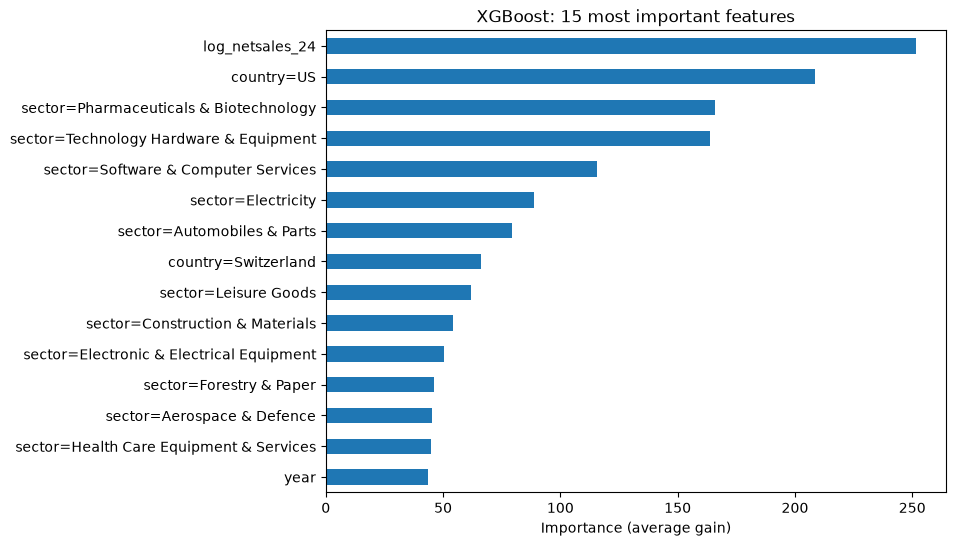

In [15]:
# Retrain each model with its best settings and compare on the validation set
results = {}

ridge = Ridge(alpha=1).fit(X_train_dv, y_train)
results['Ridge (alpha=1)'] = rmse(y_val, ridge.predict(X_val_dv))

dt = DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=1).fit(X_train_dv, y_train)
results['Decision tree (depth 12, leaf 50)'] = rmse(y_val, dt.predict(X_val_dv))

rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=1, n_jobs=-1).fit(X_train_dv, y_train)
results['Random forest (100 trees, leaf 5)'] = rmse(y_val, rf.predict(X_val_dv))

xgb_params = {'eta': 0.1, 'max_depth': 6, 'min_child_weight': 1,
              'objective': 'reg:squarederror', 'seed': 1, 'verbosity': 1}
xgb_model = xgb.train(xgb_params, dtrain, num_boost_round=240)
results['XGBoost (eta 0.1, depth 6, 240 rounds)'] = rmse(y_val, xgb_model.predict(dval))

comparison = pd.DataFrame({'validation_rmse': results})
comparison['typical_error_factor'] = np.exp(comparison['validation_rmse'])
comparison = comparison.sort_values('validation_rmse')
print(comparison.round(3), '\n')

# Which features did XGBoost rely on most?
importance = pd.Series(xgb_model.get_score(importance_type='gain')).sort_values()
importance.tail(15).plot(kind='barh', figsize=(8, 6))
plt.xlabel('Importance (average gain)')
plt.title('XGBoost: 15 most important features')
plt.show()

**5.5 Model comparison**

| Model | Best settings | Validation RMSE | Typical error |
|---|---|---|---|
| **XGBoost** | eta 0.1, max_depth 6, min_child_weight 1, 240 rounds | **0.795** | **× 2.21** |
| Random forest | 100 trees, no depth limit, min_samples_leaf 5 | 0.843 | × 2.32 |
| Ridge | alpha 1 | 0.917 | × 2.50 |
| Decision tree | max_depth 12, min_samples_leaf 50 | 0.939 | × 2.56 |

**XGBoost is chosen as the final model.** The tree ensembles clearly beat the linear model, consistent with the EDA finding that sector matters in combination with company size.

The feature importance chart supports this: net sales is the most important feature, followed by country (US) and a range of sectors such as pharmaceuticals & biotechnology, technology hardware and software. US-based companies appear to spend differently on R&D from otherwise similar companies elsewhere.

## 6. Final model

The chosen model is retrained on the training and validation data together and evaluated once on the test set.

In [16]:
# 1. Combine the training and validation companies
df_full_train = df_clean[df_clean['company'].isin(companies_full_train)]
X_full_train = prepare_features(df_full_train)
X_test = prepare_features(df_test)

full_train_medians = X_full_train[numerical].median()
for X in [X_full_train, X_test]:
    X[numerical] = X[numerical].fillna(full_train_medians)
    X[categorical] = X[categorical].fillna('unknown')

y_full_train = np.log1p(df_full_train['rnd_24']).values

dv_final = DictVectorizer(sparse=False)
X_full_train_dv = dv_final.fit_transform(X_full_train.to_dict(orient='records'))
X_test_dv = dv_final.transform(X_test.to_dict(orient='records'))
features_final = list(dv_final.get_feature_names_out())

dfull = xgb.DMatrix(X_full_train_dv, label=y_full_train, feature_names=features_final)
dtest = xgb.DMatrix(X_test_dv, label=y_test, feature_names=features_final)

# 2. Train the final model and score it once on the test set
final_model = xgb.train(xgb_params, dfull, num_boost_round=240)
y_pred_test = final_model.predict(dtest)
test_rmse = rmse(y_test, y_pred_test)
print(f'Test RMSE: {test_rmse:.3f}  (typically off by a factor of {np.exp(test_rmse):.2f})')

within = np.abs(y_test - y_pred_test) <= test_rmse
print(f'Share of test predictions within the typical range: {within.mean():.0%}\n')

# 3. One example: a UK company from the test set
example = df_test[(df_test['new_country'] == 'UK') & (df_test['year'] == 2024)].iloc[[0]]
pos = df_test.index.get_loc(example.index[0])
print(example[['company_name', 'year', 'icb3_name', 'netsales_24', 'emp', 'rnd_24']].to_string())
print(f"\nActual R&D: €{example['rnd_24'].iloc[0]:,.0f}m   Predicted: €{np.expm1(y_pred_test[pos]):,.0f}m")

Test RMSE: 0.780  (typically off by a factor of 2.18)
Share of test predictions within the typical range: 74%

   company_name  year                        icb3_name  netsales_24      emp  rnd_24
33      GSK PLC  2024  Pharmaceuticals & Biotechnology     37,839.8 68,629.0 6,865.8

Actual R&D: €6,866m   Predicted: €4,336m


**6. Final model**

XGBoost was retrained on the training and validation companies together (80% of companies) with the best settings from section 5, and evaluated once on the test set (the remaining 20% of companies, never used for any decision).

- **Test RMSE: 0.780** (typical error × 2.18), in line with the validation RMSE (0.795). The model generalises to companies it has not seen before.
- 74% of test predictions fall within the typical range (actual R&D between the prediction ÷ 2.18 and × 2.18).
- Example: GSK (2024) reported R&D of €6,866m against a predicted €4,336m: higher than expected for a pharmaceutical company of its size, but within the typical range.